# Practical Assignment 5: Ensemble Learning and Performance Evaluation

**Course:** Artificial Intelligence and Machine Learning (AIML)  
**Practical:** 5  
**Application:** Handwritten Digit Recognition  
**Dataset:** Scikit-learn Digits Dataset  
**Student Name:** Hrishikesh Koshti  
**Roll Number:** 17  
**PRN:** 202401040054

This practical uses small grayscale images of handwritten digits (0–9). The task is to classify each image into its correct digit using individual classifiers and ensemble learning techniques.

## 1. Aim

To implement and evaluate **Stacking, AdaBoost, and Majority Voting** for handwritten digit recognition and compare their performance with individual machine-learning classifiers using classification metrics.

## 2. Problem Statement

Handwritten digits can look different because people write numbers in different styles. A machine-learning model must learn patterns from digit images and predict the correct digit from 0 to 9.

In this practical, the Digits dataset is used to train and evaluate individual classifiers and three ensemble methods:

- **Stacking:** combines predictions from base classifiers using a trained meta-classifier.
- **AdaBoost:** trains weak learners sequentially, focusing more on samples that previous learners classified incorrectly.
- **Voting:** combines predictions from multiple classifiers using majority voting.

All models are evaluated on the same held-out test set.

## 3. Objectives

1. Load and explore the Handwritten Digits dataset.
2. Preprocess the data and create a stratified training and testing split.
3. Train individual classifiers.
4. Implement Stacking with Logistic Regression as the meta-classifier.
5. Implement AdaBoost with a shallow decision tree as the weak learner.
6. Implement a hard-voting ensemble using majority voting.
7. Compare all models using accuracy, macro precision, macro recall, macro F1-score, and confusion matrices.
8. Interpret the results and discuss use cases, limitations, and future improvements.

## 4. Theory and Mathematical Background

### 4.1 Ensemble Learning

Ensemble learning combines predictions from multiple machine-learning models to produce a final prediction. It can improve reliability when the models make different errors.

### 4.2 Stacking

Stacking trains multiple base classifiers and uses their predictions as inputs to a second-level model called a **meta-classifier**. Here, Logistic Regression is used as the meta-classifier.

### 4.3 AdaBoost

AdaBoost (Adaptive Boosting) trains weak learners one after another. It gives greater importance to training samples that earlier learners misclassified. The final prediction combines the learners using their learned weights.

### 4.4 Majority Voting

In hard voting, each classifier predicts one digit. The digit receiving the largest number of votes is selected:

\[
\hat{y} = \operatorname{mode}\{h_1(x),h_2(x),\ldots,h_m(x)\}
\]

### 4.5 Classification Metrics

- **Accuracy:** proportion of all test samples classified correctly.
- **Precision:** among samples predicted as a class, the proportion that truly belongs to that class.
- **Recall:** among samples belonging to a class, the proportion correctly identified.
- **F1-score:** harmonic mean of precision and recall.

\[
Precision = \frac{TP}{TP+FP}, \quad
Recall = \frac{TP}{TP+FN}
\]

\[
F1 = 2\cdot\frac{Precision\cdot Recall}{Precision+Recall}
\]

Macro averages calculate the metric separately for each digit and then give all ten digits equal weight. A confusion matrix shows actual digits against predicted digits.

## 5. Algorithms

### 5.1 Stacking Algorithm
1. Select diverse base classifiers.
2. Generate out-of-fold predictions from the base classifiers on the training data.
3. Use these predictions to train a Logistic Regression meta-classifier.
4. Refit the base classifiers on the complete training set.
5. Use the meta-classifier to combine their predictions for unseen images.

### 5.2 AdaBoost Algorithm
1. Assign equal initial weights to training samples.
2. Train a weak learner.
3. Calculate its weighted classification error.
4. Increase the importance of incorrectly classified samples.
5. Repeat for the selected number of learners.
6. Combine the weak learners to make the final prediction.

### 5.3 Majority Voting Algorithm
1. Train the selected base classifiers.
2. Obtain one predicted digit from each classifier.
3. Count the votes for each digit.
4. Select the digit with the largest number of votes.

## 6. Required Libraries

- **NumPy:** numerical operations.
- **Pandas:** results tables.
- **Matplotlib and Seaborn:** digit images and evaluation plots.
- **Scikit-learn:** dataset, preprocessing, classifiers, ensemble methods, and metrics.

The Digits dataset is included with scikit-learn, so no separate dataset download is required.

## 7. Dataset Description and Preprocessing

The scikit-learn Digits dataset contains **1,797 grayscale images** of handwritten digits from 0 to 9. Each image is 8 × 8 pixels. The pixel values are represented as 64 numerical features, and the target is one of ten digit classes.

The data is split into 80% training data and 20% testing data. Stratification preserves the approximate class distribution in both sets. Feature scaling is used for Logistic Regression, K-Nearest Neighbours, and Support Vector Machine models.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

RANDOM_STATE = 42

In [2]:
# Load the built-in handwritten digits dataset
digits = load_digits()
X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("Digit classes:", np.unique(y))
print("Number of samples:", len(y))

Dataset shape: (1797, 64)
Number of classes: 10
Digit classes: [0 1 2 3 4 5 6 7 8 9]
Number of samples: 1797


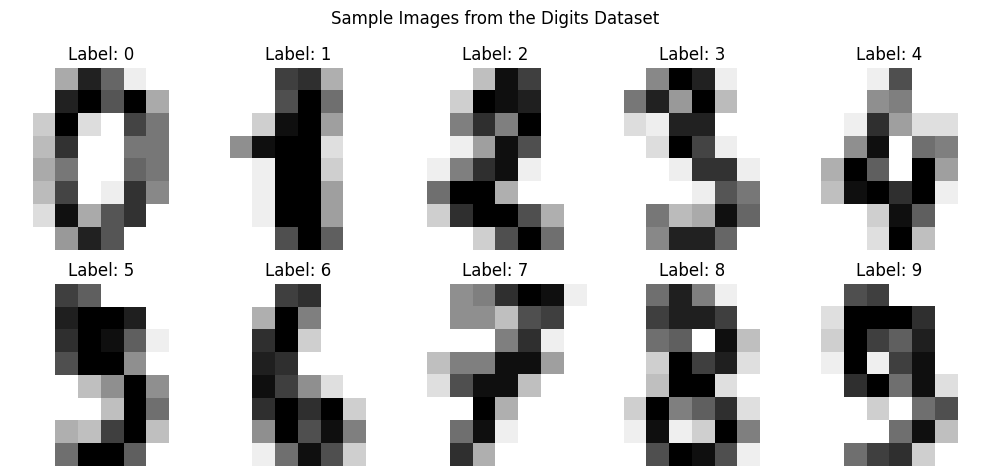

In [3]:
# Display sample handwritten digit images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for digit, ax in enumerate(axes.ravel()):
    sample_index = np.where(y == digit)[0][0]
    ax.imshow(digits.images[sample_index], cmap="gray_r")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")

plt.suptitle("Sample Images from the Digits Dataset")
plt.tight_layout()
plt.show()

0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


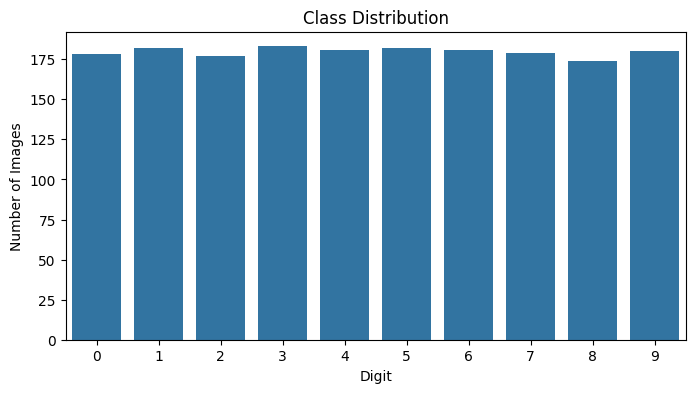

In [4]:
# Check the number of samples in each digit class
class_counts = pd.Series(y).value_counts().sort_index()
print(class_counts)

plt.figure(figsize=(8, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.title("Class Distribution")
plt.show()

In [5]:
# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1437
Testing samples: 360


## 8. Implementation and Outputs

The following individual classifiers are used as base models:

- Logistic Regression
- K-Nearest Neighbours (KNN)
- Support Vector Machine (SVM with RBF kernel)
- Random Forest

Pipelines apply median imputation and scaling where required. The same training and testing split is used for a fair comparison.

In [6]:
# Define base classifiers
base_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

# Train base models
for name, model in base_models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
KNN trained successfully.
SVM trained successfully.
Random Forest trained successfully.


In [7]:
# Stacking ensemble with Logistic Regression meta-classifier
stack_estimators = [(name, model) for name, model in base_models.items()]

stacking_model = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)
print("Stacking ensemble trained successfully.")

Stacking ensemble trained successfully.


In [8]:
# AdaBoost ensemble using a decision stump as the weak learner
weak_learner = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)

# Compatibility with newer and older scikit-learn versions
try:
    adaboost_model = AdaBoostClassifier(
        estimator=weak_learner,
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    )
except TypeError:
    adaboost_model = AdaBoostClassifier(
        base_estimator=weak_learner,
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    )

adaboost_model.fit(X_train, y_train)
print("AdaBoost ensemble trained successfully.")

AdaBoost ensemble trained successfully.


In [9]:
# Hard Voting ensemble
voting_estimators = [(name, model) for name, model in base_models.items()]

voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting="hard",
    n_jobs=-1
)

voting_model.fit(X_train, y_train)
print("Majority Voting ensemble trained successfully.")

Majority Voting ensemble trained successfully.


## 9. Performance Evaluation and Comparison

Every trained model is evaluated on the same test set. Macro precision, recall, and F1-score are used so that each digit class contributes equally to the overall metric.

In [10]:
# Combine base and ensemble models for evaluation
all_models = {**base_models}
all_models["Stacking"] = stacking_model
all_models["AdaBoost"] = adaboost_model
all_models["Majority Voting"] = voting_model

results = []
predictions = {}

for name, model in all_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-score (Macro)", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Stacking,0.9889,0.9890,0.9887,0.9888
1,SVM,0.9750,0.9760,0.9748,0.9748
2,Majority Voting,0.9750,0.9756,0.9748,0.9746
3,Logistic Regression,0.9722,0.9721,0.9719,0.9719
4,KNN,0.9639,0.9646,0.9637,0.9634
5,Random Forest,0.9639,0.9644,0.9635,0.9634
6,AdaBoost,0.8250,0.8331,0.8245,0.8258


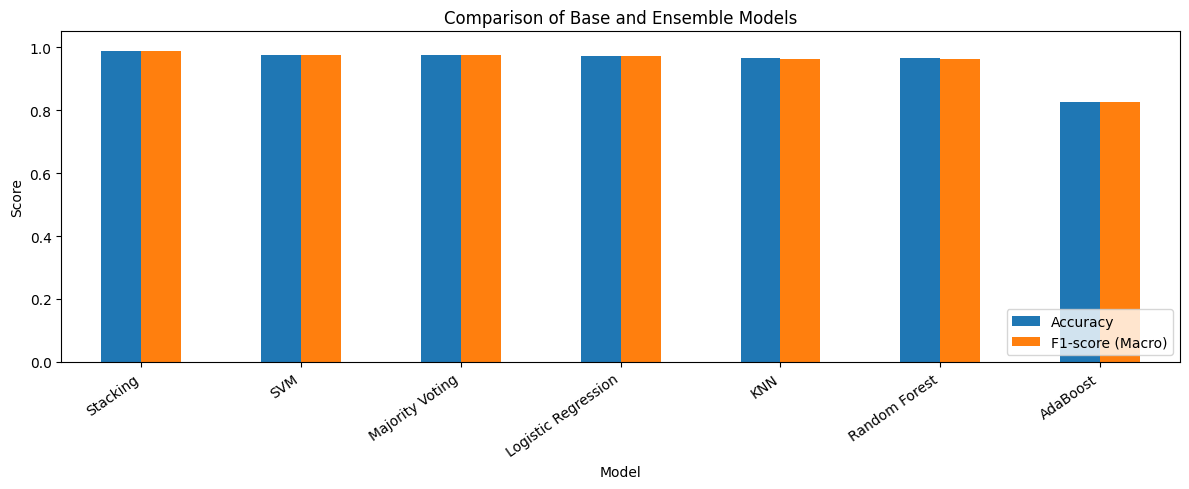

In [11]:
# Compare model accuracy and macro F1-score
plot_data = results_df.set_index("Model")[["Accuracy", "F1-score (Macro)"]]

plot_data.plot(kind="bar", figsize=(12, 5))
plt.title("Comparison of Base and Ensemble Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

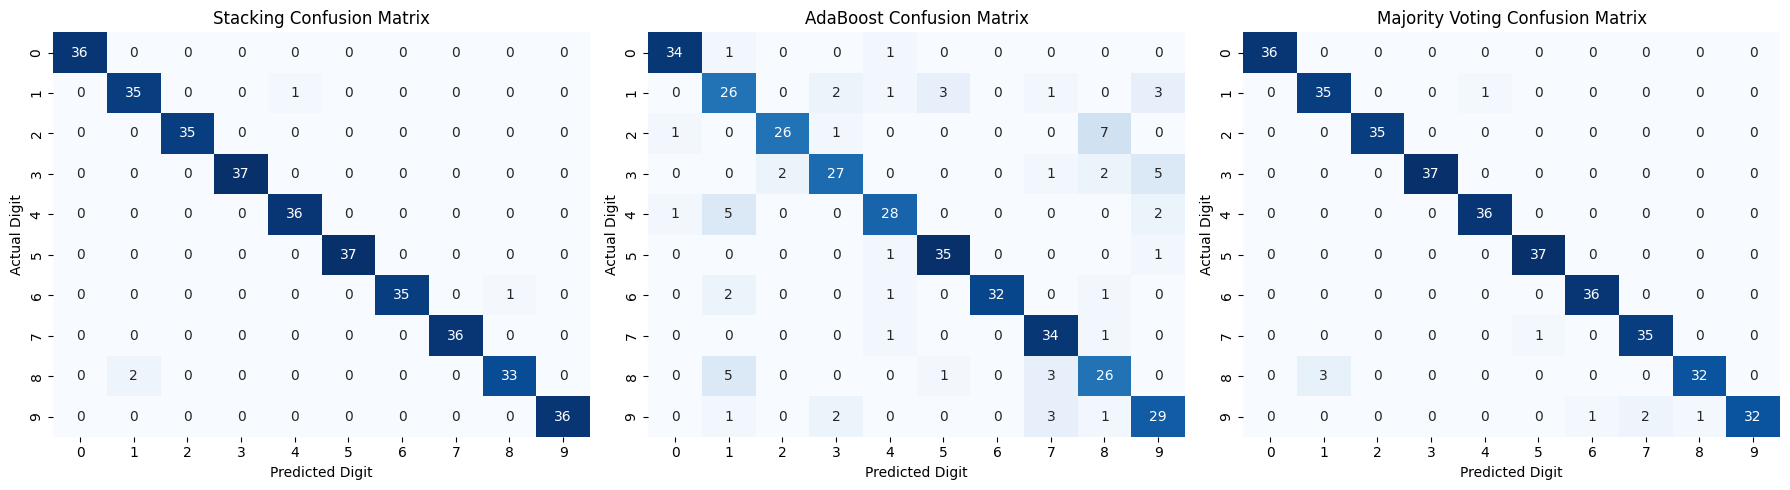

In [12]:
# Confusion matrix for each ensemble method
ensemble_names = ["Stacking", "AdaBoost", "Majority Voting"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, ensemble_names):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Digit")
    ax.set_ylabel("Actual Digit")

plt.tight_layout()
plt.show()

In [13]:
# Detailed classification report for the best-performing model
best_model_name = results_df.loc[0, "Model"]
print("Best model based on Macro F1-score:", best_model_name)
print()
print(classification_report(
    y_test,
    predictions[best_model_name],
    zero_division=0
))

Best model based on Macro F1-score: Stacking

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      0.97      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.97      0.94      0.96        35
           9       1.00      1.00      1.00        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



## 10. Conclusion and Critical Analysis

This practical implements three ensemble learning techniques—Stacking, AdaBoost, and Majority Voting—and compares them with individual classifiers for handwritten digit recognition.

- The model with the highest test accuracy was **Stacking**, with an accuracy of **0.9889**.
- The model with the highest macro F1-score was **Stacking**, with a macro F1-score of **0.9889**.
- Compared with the strongest individual classifier, the best ensemble model **improved** the measured performance.
### When to Use Each Method

- **Stacking:** useful when different base classifiers have complementary strengths and a meta-classifier can learn how to combine them. It is more computationally expensive.
- **AdaBoost:** useful when sequential weak learners can improve classification by focusing on difficult training samples. It can be sensitive to noisy or mislabeled data.
- **Majority Voting:** useful when several classifiers perform reasonably well and a simple combination is desired. Hard voting is easy to explain.
- **A single classifier:** may be preferable when it already performs well and simplicity or faster prediction is important.

### Limitations

1. The Digits dataset contains small 8 × 8 images and may not represent the variety and resolution of real-world handwriting.
2. Results depend on the train-test split and model settings.
3. The experiment evaluates predictive metrics but does not benchmark training time or prediction time.
4. Performance on this dataset does not guarantee performance on photographs or scanned documents from different sources.